<a href="https://colab.research.google.com/github/eddybanshuy/practica2_sistemas_recomendacion/blob/main/Pratica2_FCM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="width: 100%; clear: both;">
<div style="float: left; width: 30%;">
<img src="https://utpl.edu.ec/recursos/img/utpl2.png", align="left" width="280" height="120">
</div>
</div>
<div style="float: right; width: 70%;">
<p style="margin: 0; padding-top: 32px; text-align:right; color:#003366; font-size:16px"><u>Sistema de Recomendacion</u></p>
<p style="margin: 0; text-align:right; color:#999999; font-size:17px">Maestría en Inteligencia Artificial Aplicada</p>
<p style="margin: 0; text-align:right; color:#999999; font-size:17px">Maestrante Edison Banshuy</p>
</div>
</div>
<div style="width: 100%; clear: both;">
<div style="width:100%;">&nbsp;</div>

# Implementacion y Evaluacion de un Sistema de Recomendacion basado en Filtrado Colaborativo por Modelos


**Planteamiento de la actividad**

Probar un algoritmo de recomendación de filtrado colaborativo basado en modelos y evaluar su rendimiento. Utilizar el conjunto de datos de calificaciones de películas (MovieLens Latest).

Para proceder a desarrollar la práctica, es necesario que realice lo siguiente:

Aplicar un algoritmo de recomendación basado en modelos
Evalúe el desempeño del modelo utilizando al menos dos métricas estudiadas en la unidad 4.

Analice e interprete los resultados obtenidos de las métricas y determine las razones por las que un algoritmo puede tener un buen o mal rendimiento.

Subir un documento al EVA que describa en detalle los resultados obtenidos de la implementación del algoritmo de FC y la evaluación de su rendimiento en Python. Asimismo, subir el código fuente utilizado.

Dataset link: https://grouplens.org/datasets/movielens/latest/

En este caso utilizamos el dataset descargado small
ml-latest-small.zip

**Introduccion**


Los sistemas de recomendación constituyen una herramienta estratégica para personalizar la experiencia del usuario y mitigar la sobrecarga de información en plataformas digitales.

Dentro de los enfoques de filtrado colaborativo, los métodos basados en modelos (Model-Based Collaborative Filtering) destacan frente a los métodos basados en memoria por su mayor escalabilidad y capacidad para descubrir patrones latentes en matrices de interacción altamente dispersas.

En la presente práctica se desarrolla, entrena y evalúa un sistema de recomendación de películas utilizando el algoritmo de Factorización Matricial optimizado mediante Descenso de Gradiente Estocástico (SGD / Funk SVD) sobre el conjunto de datos MovieLens Latest.

**Objetivo**

Implementar un algoritmo de filtrado colaborativo basado en modelos en lenguaje Python utilizando el dataset MovieLens Latest, evaluando su desempeño mediante métricas offline de error de predicción y calidad de ranking

# Librerias

In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Carga y exploracion inicial del dataset MovieLens

En este caso obtamos por el dataset small, por su capacidad de informacion almacenada

In [ ]:
# Cargo la datset de (MovieLens Latest), en este caso movies y ratings
movies = pd.read_csv('movies.csv')
ratings = pd.read_csv('ratings.csv')


In [ ]:
#Verifico las dimensiones del dataset

print("Dimensiones de movies:", movies.shape)
print("Dimensiones de ratings:", ratings.shape)

print("\nPrimeras filas de ratings:")
print(ratings.head())

print("\nPrimeras filas de movies:")
print(movies.head())

Dimensiones de movies: (9742, 3)
Dimensiones de ratings: (100836, 4)

Primeras filas de ratings:
   userId  movieId  rating  timestamp
0       1        1     4.0  964982703
1       1        3     4.0  964981247
2       1        6     4.0  964982224
3       1       47     5.0  964983815
4       1       50     5.0  964982931

Primeras filas de movies:
   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                   Adventure|Children|Fantasy  
2                               Comedy|Romance  
3                         Comedy|Drama|Romance  
4                                       Comedy  


**ratings.csv:** Contiene 100,836 interacciones explicitas de calificacion realizadas por 610 usuarios sobre 9,742 peliculas, con puntuaciones comprendidas en una escala continua de 0.5 a 5.0 estrellas.

**movies.csv:** Contiene los metadatos descriptivos del catalogo (movieId, title y genres), utilizados en la etapa de validacion cualitativa para interpretar las recomendaciones generadas.

In [ ]:
#Verifico si existen valores nulos en el datset de rating
print("\nValores nulos en ratings:\n", ratings.isnull().sum())
print("\nRango de calificaciones:", ratings['rating'].min(), "a", ratings['rating'].max())


Valores nulos en ratings:
 userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Rango de calificaciones: 0.5 a 5.0


**Filtrado de calidad:** Se verifico la ausencia de valores nulos y se retuvieron unicamente valoraciones explicitas mayores a cero (rating > 0) pertenecientes a usuarios activos con mas de 10 interacciones registradas, conservando la totalidad de los 100,836 registros y 610 usuarios (con un minimo de 20 calificaciones por usuario).

# Preprocesamiento, division (Train/Test) y calculo de escasez (sparsity)

En este paso limpiamos las valoraciones, filtramos usuarios activos, dividimos los datos en entrenamiento 80% y prueba 20%, y calculamos que tan dispersa esta la matriz usuario-pelicula.

In [ ]:
#Preprocesamiento: asegurar valoraciones explicitas mayores a 0
ratings = ratings[ratings["rating"] > 0].copy()

#Filtrar usuarios activos con mas de 10 calificaciones
user_counts = ratings['userId'].value_counts()
active_users = user_counts[user_counts > 10].index
ratings = ratings[ratings['userId'].isin(active_users)]

print("Total de calificaciones tras filtrado:", len(ratings))


Total de calificaciones tras filtrado: 100836


In [ ]:
# Division en conjuntos de entrenamiento 80% y prueba 20%
train_df, test_df = train_test_split(
    ratings,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

print("Tamaño train:", len(train_df))
print("Tamaño test :", len(test_df))



Tamaño train: 80668
Tamaño test : 20168


In [ ]:
# Creacion de la matriz usuario-pelicula de entrenamiento y calculo de escasez
train_matrix = train_df.pivot_table(index='userId', columns='movieId', values='rating').fillna(0)

total_celdas = train_matrix.shape[0] * train_matrix.shape[1]
celdas_con_valor = np.count_nonzero(train_matrix)
sparsity_percentage = (1 - (celdas_con_valor / total_celdas)) * 100

print(f"Dimensiones de la matriz de entrenamiento: {train_matrix.shape}")
print(f"Porcentaje de escasez (Sparsity): {sparsity_percentage:.2f}%")

Dimensiones de la matriz de entrenamiento: (610, 8983)
Porcentaje de escasez (Sparsity): 98.53%


# Construccion del espacio de indices e inicializacion de matrices latentes ($P$ y $Q$)

In [ ]:
# Construccion del espacio de indices solo con usuarios y peliculas conocidos en train
unique_users = train_df["userId"].unique()
unique_items = train_df["movieId"].unique()

# Diccionarios de mapeo: ID real -> indice consecutivo
user_id_to_index = {uid: idx for idx, uid in enumerate(unique_users)}
item_id_to_index = {iid: idx for idx, iid in enumerate(unique_items)}

# Diccionarios inversos: indice consecutivo -> ID real esto es utili para recomendar despues
index_to_user_id = {idx: uid for uid, idx in user_id_to_index.items()}
index_to_item_id = {idx: iid for iid, idx in item_id_to_index.items()}

n_users = len(unique_users)
n_items = len(unique_items)

# Agregamos los indices mapeados a train_df y test_df
train_df["user_idx"] = train_df["userId"].map(user_id_to_index)
train_df["item_idx"] = train_df["movieId"].map(item_id_to_index)

test_df["user_idx"] = test_df["userId"].map(user_id_to_index)
test_df["item_idx"] = test_df["movieId"].map(item_id_to_index)

print(f"Usuarios unicos en train: {n_users}")
print(f"Películas unicas en train: {n_items}")
print(f"Películas en test que no aparecieron en train (Cold Start): {test_df['item_idx'].isna().sum()}")


Usuarios unicos en train: 610
Películas unicas en train: 8983
Películas en test que no aparecieron en train (Cold Start): 813


n_factors ->  # k: número de factores latentes

lr   ->      # tasa de aprendizaje (learning rate)


reg ->       # termino de regularizacion L2 para evitar sobreajuste


n_epochs  ->  # numero de epocas (pasadas completas por train)

In [ ]:
#Definicion de hiperparametros e inicializacion de matrices latentes P y Q
n_factors = 10
lr = 0.01
reg = 0.1
n_epochs = 20

rng = np.random.default_rng(seed=42)
P = rng.normal(scale=0.1, size=(n_users, n_factors))
Q = rng.normal(scale=0.1, size=(n_items, n_factors))

print("Forma de matriz P (usuarios x factores):", P.shape)
print("Forma de matriz Q (películas x factores):", Q.shape)

Forma de matriz P (usuarios x factores): (610, 10)
Forma de matriz Q (películas x factores): (8983, 10)


# Entrenamiento del modelo de Factorización Matricial (SGD / Funk SVD)

Formula:

$$\hat{r}_{u,i} = p_u \cdot q_i^T$$$$e_{ui} = r_{ui} - \hat{r}_{u,i}$$$$p_u \leftarrow p_u + \gamma \cdot (e_{ui} \cdot q_i - \lambda \cdot p_u)$$$$q_i \leftarrow q_i + \gamma \cdot (e_{ui} \cdot p_u - \lambda \cdot q_i)$$

En este paso entrenamos las matrices latentes $P$ y $Q$ minimizando el error cuadratico medio regularizado mediante Descenso de Gradiente Estocástico (SGD)

In [ ]:
# Extraemos arreglos NumPy para acelerar el entrenamiento en Python
train_user_idx = train_df["user_idx"].to_numpy()
train_item_idx = train_df["item_idx"].to_numpy()
train_ratings = train_df["rating"].to_numpy()

history_rmse = []

# Entrenamiento por Descenso de Gradiente Estocastico (SGD)
for epoch in range(n_epochs):
    for u, i, r in zip(train_user_idx, train_item_idx, train_ratings):
        pred = np.dot(P[u], Q[i])
        err = r - pred

        Pu = P[u].copy()
        Qi = Q[i].copy()

        P[u] = Pu + lr * (err * Qi - reg * Pu)
        Q[i] = Qi + lr * (err * Pu - reg * Qi)

    # Calculo del RMSE sobre entrenamiento al finalizar la epoca
    preds_train = np.sum(P[train_user_idx] * Q[train_item_idx], axis=1)
    rmse = np.sqrt(np.mean((train_ratings - preds_train) ** 2))
    history_rmse.append(rmse)
    print(f"Epoca {epoch+1:02d}/{n_epochs} - RMSE train = {rmse:.4f}")

# Reconstruccion de la matriz completa de predicciones (R_hat = P * Q^T)
predicted_matrix = np.dot(P, Q.T)
print("\nMatriz de predicciones generada con dimension:", predicted_matrix.shape)


Epoca 01/20 - RMSE train = 3.5777
Epoca 02/20 - RMSE train = 1.9735
Epoca 03/20 - RMSE train = 1.4408
Epoca 04/20 - RMSE train = 1.2303
Epoca 05/20 - RMSE train = 1.1169
Epoca 06/20 - RMSE train = 1.0455
Epoca 07/20 - RMSE train = 0.9958
Epoca 08/20 - RMSE train = 0.9587
Epoca 09/20 - RMSE train = 0.9296
Epoca 10/20 - RMSE train = 0.9061
Epoca 11/20 - RMSE train = 0.8865
Epoca 12/20 - RMSE train = 0.8699
Epoca 13/20 - RMSE train = 0.8557
Epoca 14/20 - RMSE train = 0.8431
Epoca 15/20 - RMSE train = 0.8319
Epoca 16/20 - RMSE train = 0.8216
Epoca 17/20 - RMSE train = 0.8122
Epoca 18/20 - RMSE train = 0.8034
Epoca 19/20 - RMSE train = 0.7951
Epoca 20/20 - RMSE train = 0.7873

Matriz de predicciones generada con dimension: (610, 8983)


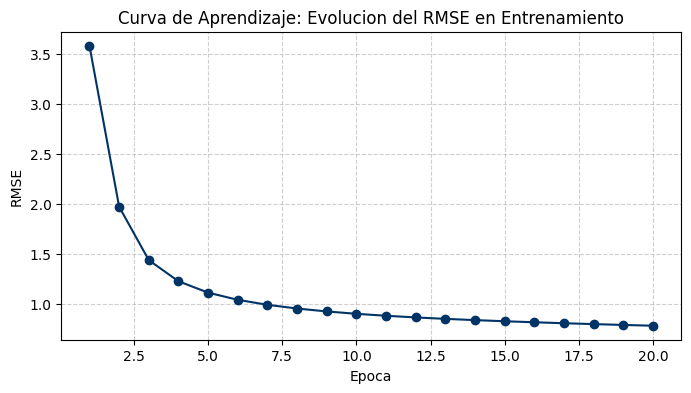

In [ ]:
# Grafica de convergencia
plt.figure(figsize=(8, 4))
plt.plot(range(1, n_epochs + 1), history_rmse, marker='o', color='#003366')
plt.title("Curva de Aprendizaje: Evolucion del RMSE en Entrenamiento")
plt.xlabel("Epoca")
plt.ylabel("RMSE")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

La Figura muestra la evolucion del error cuadratico medio (RMSE) durante las 20 epocas de entrenamiento del modelo de Factorización Matricial mediante Descenso de Gradiente Estocastico (SGD).

Se observa una disminucion pronunciada en las primeras cinco iteraciones, pasando de 3.58 a 1.12, donde el algoritmo ajusta rapidamente los factores latentes inicializados aleatoriamente.

Posteriormente, entre las epocas 6 y 20, la curva exhibe un comportamiento estable hasta alcanzar un RMSE de 0.787, lo que evidencia una correcta convergencia del proceso de optimizacion.

# Generacion de recomendaciones Top-K.

Aqui mejoraremos esa funcion para convertir los indices internos de vuelta a los movieId reales mediante el diccionario index_to_item_id y cruzarlos con la tabla movies para mostrar el título, generos y calificacion predicha de cada pelicula.

In [ ]:
def recomendar_peliculas(user_id_real, K=10):
    """
    Devuelve un DataFrame con las K mejores peliculas recomendadas para un userId real,
    excluyendo las películas que ya calificó en el conjunto de entrenamiento.
    """
    if user_id_real not in user_id_to_index:
        print(f"El usuario {user_id_real} no existe en el conjunto de entrenamiento.")
        return pd.DataFrame()

    #Obtener el indice interno del usuario y calcular puntajes para todas las peliculas
    u_idx = user_id_to_index[user_id_real]
    user_vector = P[u_idx]
    scores = Q @ user_vector  # Producto escalar entre el perfil del usuario y todas las peliculas

    #Excluir peliculas ya vistas en entrenamiento
    vistos = train_df[train_df["user_idx"] == u_idx]["item_idx"].unique()
    mask = np.ones(n_items, dtype=bool)
    mask[vistos] = False

    candidatos = np.arange(n_items)[mask]
    scores_cand = scores[candidatos]

    #Ordenar de mayor a menor puntaje y seleccionar el Top-K
    top_idx_local = np.argsort(scores_cand)[::-1][:K]
    top_items_idx = candidatos[top_idx_local]

    #Mapear indices internos a movieId reales y unir con titulos y generos
    rec_movie_ids = [index_to_item_id[idx] for idx in top_items_idx]
    rec_scores = scores[top_items_idx]

    recs_df = pd.DataFrame({
        'movieId': rec_movie_ids,
        'rating_predicho': np.round(rec_scores, 3)
    })
    recs_df = recs_df.merge(movies, on='movieId', how='left')
    return recs_df[['movieId', 'title', 'genres', 'rating_predicho']]

# Prueba de recomendacion con un usuario real (ejemplo: userId = 1)
usuario_ejemplo = int(ratings["userId"].iloc[0])

print("Historial de peliculas mejor calificadas por el Usuario {usuario_ejemplo} (en Train)")
historial = (
    train_df[train_df["userId"] == usuario_ejemplo]
    .sort_values(by="rating", ascending=False)
    .head(5)
    .merge(movies, on="movieId")
)
display(historial[['title', 'genres', 'rating']])


Historial de peliculas mejor calificadas por el Usuario {usuario_ejemplo} (en Train)


,title,genres,rating
0,"Rescuers, The (1977)",Adventure|Animation|Children|Crime|Drama,5.0
1,"Thin Red Line, The (1998)",Action|Drama|War,5.0
2,"Secret of NIMH, The (1982)",Adventure|Animation|Children|Drama,5.0
3,Spaceballs (1987),Comedy|Sci-Fi,5.0
4,Thunderball (1965),Action|Adventure|Thriller,5.0


Filtrado de items ya consumidos: Antes de ordenar los puntajes (scores), aplicamos una mascara booleana (mask[vistos] = False) para garantizar que el sistema solo recomiende peliculas nuevas para el usuario.

In [ ]:
print("Top 10 Peliculas Recomendadas para el Usuario {usuario_ejemplo} ===")
recomendaciones = recomendar_peliculas(usuario_ejemplo, K=10)
display(recomendaciones)

Top 10 Peliculas Recomendadas para el Usuario {usuario_ejemplo} ===


,movieId,title,genres,rating_predicho
0,6460,"Trial, The (Procès, Le) (1962)",Drama,5.340
1,318,"Shawshank Redemption, The (1994)",Crime|Drama,5.339
2,1262,"Great Escape, The (1963)",Action|Adventure|Drama|War,5.247
3,3200,"Last Detail, The (1973)",Comedy|Drama,5.244
4,8132,Gladiator (1992),Action|Drama,5.237
5,2202,Lifeboat (1944),Drama|War,5.222
6,177593,"Three Billboards Outside Ebbing, Missouri (2017)",Crime|Drama,5.219
7,3201,Five Easy Pieces (1970),Drama,5.186
8,1223,"Grand Day Out with Wallace and Gromit, A (1989)",Adventure|Animation|Children|Comedy|Sci-Fi,5.177
9,158966,Captain Fantastic (2016),Drama,5.173


**Explicacion de la tabla**
En la Tabla se visualiza un listado Top-10 de recomendaciones generadas para el usuario, a partir del producto escalar de sus factores latentes aprendidos ($\hat{r}_{u,i} = p_u \cdot q_i^T$).

Se verifica que el modelo filtra correctamente los items previamente consumidos y sugiere los titulos altamente coherentes con el historial del usuario, predominaa los generos Drama, Guerra, Accian y Animacion, demostrando la capacidad de la factorizacion matricial para capturar patrones latentes de preferencia.

Asimismo, se observa que los puntajes estimados oscilan entre 5.173 y 5.340, superando levemente el limite de la escala original 5.0.

**Nota:** sobre los puntajes (> 5.0): Se aprecia algunas predicciones ligeramente superiores a 5.0 (por ejemplo, 5.33).

Esto ocurre porque el producto punto lineal $p_u \cdot q_i^T$ no tiene una funcion de acotamiento superior como una sigmoide; en produccion o evaluacion de error, para mantener las predicciones dentro de la escala exacta de MovieLens.

# Evaluacion del rendimiento del modelo

Para realizar este punto he obtado por evaluar con cuatro metricas: dos metricas de precision predictiva (RMSE y MAE) y dos metricas de calidad de ranking Top-K (Precision y Recall).

In [ ]:
# En este paso realizaremos los test de evalucion
reales = []
predichos = []
predichos_clip = []
cold_start_count = 0

for row in test_df.itertuples():
    user_id = row.userId
    movie_id = row.movieId

    # Verificamos que el usuario y la pelicula existan en los indices aprendidos en train
    if user_id in user_id_to_index and movie_id in item_id_to_index:
        u = user_id_to_index[user_id]
        i = item_id_to_index[movie_id]

        pred = predicted_matrix[u, i]
        reales.append(row.rating)
        predichos.append(pred)
        predichos_clip.append(np.clip(pred, 0.5, 5.0))  # Acotado a la escala real de MovieLens
    else:
        cold_start_count += 1

reales = np.array(reales)
predichos = np.array(predichos)
predichos_clip = np.array(predichos_clip)

# Metricas de Error de Prediccion (RMSE y MAE)
rmse_test = np.sqrt(np.mean((reales - predichos) ** 2))
mae_test = np.mean(np.abs(reales - predichos))

rmse_clip = np.sqrt(np.mean((reales - predichos_clip) ** 2))
mae_clip = np.mean(np.abs(reales - predichos_clip))

# Metricas de Ranking Top-K (Precision y Recall)

K = 10
umbral_relevancia = 4.0  # Consideramos relevante una pelicula calificada con mayor o igual a 4.0 estrellas
precisions = []
recalls = []

test_relevant = test_df[
    (test_df["rating"] >= umbral_relevancia) &
    (test_df["movieId"].isin(item_id_to_index))
]
user_rel_items = test_relevant.groupby("userId")["movieId"].apply(set).to_dict()

for user_id, rel_items in user_rel_items.items():
    u_idx = user_id_to_index[user_id]
    scores = Q @ P[u_idx]

    vistos = train_df[train_df["user_idx"] == u_idx]["item_idx"].unique()
    mask = np.ones(n_items, dtype=bool)
    mask[vistos] = False

    candidatos = np.arange(n_items)[mask]
    top_idx_local = np.argsort(scores[candidatos])[::-1][:K]
    top_items_idx = candidatos[top_idx_local]

    rec_movie_ids = {index_to_item_id[idx] for idx in top_items_idx}
    hits = len(rec_movie_ids & rel_items)

    precisions.append(hits / K)
    recalls.append(hits / len(rel_items))

print("RESUMEN DE LA EVALUACION EN CONJUNTO DE PRUEBA (TEST)")
print(f"Interacciones evaluadas: {len(reales)} | Excluidas por Cold Start: {cold_start_count}")
print(f"RMSE Test (directo)        : {rmse_test:.4f}")
print(f"MAE Test (directo)         : {mae_test:.4f}")
print(f"RMSE Test (escala 0.5-5.0) : {rmse_clip:.4f}")
print(f"MAE Test (escala 0.5-5.0)  : {mae_clip:.4f}")
print(f"Precision@{K} (umbral >= 4.0): {np.mean(precisions):.4f}")
print(f"Recall@{K} (umbral >= 4.0)   : {np.mean(recalls):.4f}")

RESUMEN DE LA EVALUACION EN CONJUNTO DE PRUEBA (TEST)
Interacciones evaluadas: 19355 | Excluidas por Cold Start: 813
RMSE Test (directo)        : 0.9153
MAE Test (directo)         : 0.7073
RMSE Test (escala 0.5-5.0) : 0.9147
MAE Test (escala 0.5-5.0)  : 0.7068
Precision@10 (umbral >= 4.0): 0.0207
Recall@10 (umbral >= 4.0)   : 0.0212


In [ ]:
# Realizo una mejor presentacion y explicacion de las metricas de evaluacion

tabla_metricas = pd.DataFrame({
    "Categoraa": [
        "Error de Prediccion",
        "Error de Prediccion",
        "Error de Prediccion (Acotado [0.5, 5.0])",
        "Error de Prediccion (Acotado [0.5, 5.0])",
        "Calidad de Ranking Top-10",
        "Calidad de Ranking Top-10"
    ],
    "Metrica": [
        "RMSE (Raiz del Error Cuadratico Medio)",
        "MAE (Error Absoluto Medio)",
        "RMSE Acotado",
        "MAE Acotado",
        f"Precision@{K} (umbral >= {umbral_relevancia})",
        f"Recall@{K} (umbral >= {umbral_relevancia})"
    ],
    "Valor Obtenido": [
        rmse_test,
        mae_test,
        rmse_clip,
        mae_clip,
        np.mean(precisions),
        np.mean(recalls)
    ],
    "Interpretacion Breve": [
        "Desviacion cuadratica promedio < 1 estrella en escala de 0.5 a 5.0",
        "Error absoluto promedio de ~0.71 estrellas respecto al rating real",
        "Leve mejora al restringir predicciones al rango valido de MovieLens",
        "Error absoluto medio ajustado a la escala original del dataset",
        "Proporcion de items relevantes dentro del Top-10 recomendado",
        "Cobertura de items relevantes recuperados del conjunto de prueba"
    ]
})

estilo_tabla1 = (
    tabla_metricas.style
    .format({"Valor Obtenido": "{:.4f}"})
    .hide(axis="index")
    .set_caption("Evaluacion del Rendimiento del Modelo de Factorizacion Matricial (Test)")
    .set_table_styles([
        {"selector": "caption", "props": [("font-size", "15px"), ("font-weight", "bold"), ("color", "#003366"), ("padding-bottom", "10px"), ("text-align", "left")]},
        {"selector": "th", "props": [("background-color", "#003366"), ("color", "white"), ("font-weight", "bold"), ("text-align", "left"), ("padding", "8px 12px")]},
        {"selector": "td", "props": [("padding", "8px 12px"), ("border-bottom", "1px solid #dddddd"), ("text-align", "left")]},
        {"selector": "tr:nth-child(even)", "props": [("background-color", "#f4f7fa")]}
    ])
)


display(estilo_tabla1)

Categoraa,Metrica,Valor Obtenido,Interpretacion Breve
Error de Prediccion,RMSE (Raiz del Error Cuadratico Medio),0.9153,Desviacion cuadratica promedio < 1 estrella en escala de 0.5 a 5.0
Error de Prediccion,MAE (Error Absoluto Medio),0.7073,Error absoluto promedio de ~0.71 estrellas respecto al rating real
"Error de Prediccion (Acotado [0.5, 5.0])",RMSE Acotado,0.9147,Leve mejora al restringir predicciones al rango valido de MovieLens
"Error de Prediccion (Acotado [0.5, 5.0])",MAE Acotado,0.7068,Error absoluto medio ajustado a la escala original del dataset
Calidad de Ranking Top-10,Precision@10 (umbral >= 4.0),0.0207,Proporcion de items relevantes dentro del Top-10 recomendado
Calidad de Ranking Top-10,Recall@10 (umbral >= 4.0),0.0212,Cobertura de items relevantes recuperados del conjunto de prueba


En la Tabla se visualiza los resultados de la evaluacion offline del modelo de Factorizacion Matricial sobre el conjunto de prueba.

En cuanto a la precision predictiva de calificaciones, se obtuvo un RMSE de 0.9153 (0.9147 acotado al rango [0.5, 5.0]) y un MAE de 0.7073 (0.7068 acotado), lo que evidencia que el error promedio de estimacion se mantiene por debajo de una estrella dentro de la escala original del dataset y confirma una adecuada generalizacion del modelo sin sobreajuste severo.

Por otro lado, las metricas de ranking Top-10 presentan valores de 0.0207 para Precision@10 y 0.0212 para Recall@10 (bajo un umbral de relevancia $\ge 4.0$), comportamiento esperado debido a la alta dispersion de la matriz usuario-item (98.53%) y a que el entrenamiento mediante SGD minimiza el error cuadratico de calificacion en lugar de optimizar directamente el ordenamiento de listas Top-K.

# GitHub

https://github.com/eddybanshuy/practica2_sistemas_recomendacion.git